# peptiverse_xgb_esm_raw

Published artifact `training_classifiers/half_life/xgb_wt_raw` of the PeptiVerse
repository, evaluated as distributed. The estimator is **xgb** on
**esm** sequence representations, trained on a
**raw** target.

Results are read from `results/human_serum_in_vitro/peptiverse_xgb_esm_raw/`, written by `scripts/run_all_models.py`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/model_benchmark").is_dir())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
from model_benchmark import report
from model_benchmark.metrics import measurement_interval_model

PREDICTOR = "peptiverse_xgb_esm_raw"
COHORT = "human_serum_in_vitro"
summary = report.load_result(PREDICTOR, "summary.json", COHORT)
predictions = report.load_result(PREDICTOR, "predictions.csv", COHORT)
interval_model, _ = measurement_interval_model()
noise_floor = summary.get("measurement_noise_floor_log10", 0.0)
print(f"Cohort: {summary['cohort']}, peptides: {summary['peptides']}")

Cohort: human_serum_in_vitro, peptides: 128


## Provenance of the loaded artifact

The record below describes what was actually loaded, including the conformal calibration
shipped with the artifact and the benchmark the authors stored next to it.

In [3]:
model = summary["model"]
display(pd.Series({k: v for k, v in model.items() if not isinstance(v, dict)}).to_frame("value")
        .style.set_caption("Loaded artifact"))

calibration = model.get("conformal_calibration")
if calibration:
    display(pd.Series(calibration).to_frame("value").style.set_caption("Conformal calibration shipped with the artifact"))

benchmark = model.get("published_benchmark") or {}
if benchmark:
    reported = {k: v for k, v in benchmark.items() if not isinstance(v, dict)}
    display(pd.Series(reported).to_frame("value").style.set_caption("Benchmark reported by the authors, on their own data"))

,value
name,peptiverse_xgb_esm_raw
publication,"PeptiVerse (Chatterjee Lab), Nature Communications 2026"
artifact,ChatterjeeLab/PeptiVerse:training_classifiers/half_life/xgb_wt_raw
representation,facebook/esm2_t33_650M_UR50D (sequence)
architecture,XGBoost on mean-pooled embeddings
training_records,130 sequence-based / 245 SMILES-based (reported)
native_units,hours
supports_gradient,False
batch_size,32
target_transform,raw


,value
quantile,21.159678
alpha,0.100000
format,mapie_object
calibration_size,130
quantile_level,0.907692
accepted_by_published_loader,False


## Batch interface

The published inference script scores one peptide per call. This adapter scores a batch,
as the oracles of the main library do, so the equivalence of both paths is verified
numerically rather than assumed.

In [4]:
from model_benchmark.predictors import build_predictor, verify_batch_equivalence

predictor = build_predictor(PREDICTOR)
probe = predictions.sequence.head(4).tolist()
equivalence = verify_batch_equivalence(predictor, probe)
print(f"Batched equals single-peptide path: {equivalence['within_tolerance']}")
print(f"Largest deviation: {equivalence['max_absolute_deviation']:.2e} log10 seconds")

matrix = np.array([list(seq.ljust(max(len(s) for s in probe))) for seq in probe])
print("Oracle-style call on a padded token matrix, shape", matrix.shape, "->", predictor(matrix).shape)

/home/max/repositories/pep-compass/assets/experiments/pcpsackm/datasets_analysis/test_models/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Batched equals single-peptide path: True
Largest deviation: 0.00e+00 log10 seconds
Oracle-style call on a padded token matrix, shape (4, 18) -> (4, 1)


## Question 1: point regression

Errors are reported on the base-10 logarithmic scale, where 0.3 means a factor of two.
The constant predictor that always answers the cohort median is shown next to the model,
because a model that cannot beat it carries no usable information about our peptides.

In [5]:
regression_keys = ["peptides", "mae_log10", "rmse_log10", "median_absolute_log10", "bias_log10",
                   "r2", "pearson_r", "spearman_rho", "median_error_factor"]
comparison = pd.DataFrame(
    {
        "model": {k: summary.get(k) for k in regression_keys},
        "median baseline": {k: summary["cohort_baseline"].get(k) for k in regression_keys},
    }
)
display(comparison.style.format(precision=3).set_caption("Point regression against the trivial baseline"))
print(f"Measurement noise floor (median within-peptide spread): {noise_floor:.3f} log10")
print(f"Predictions clipped at the positive floor: {summary.get('clipped_predictions', 0)}")

,model,median baseline
peptides,128.000,128.000
mae_log10,0.881,0.676
rmse_log10,1.077,0.821
median_absolute_log10,0.789,0.690
bias_log10,0.698,-0.088
r2,-0.739,-0.012
pearson_r,0.000,nan
spearman_rho,0.011,nan
median_error_factor,6.145,4.899


Measurement noise floor (median within-peptide spread): 0.000 log10
Predictions clipped at the positive floor: 0


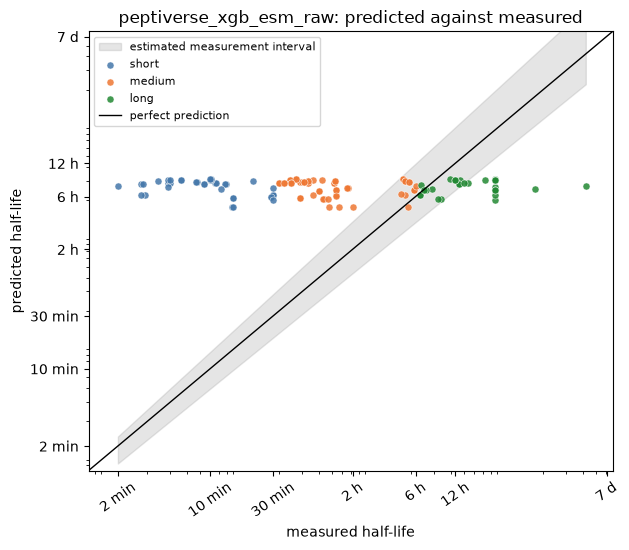

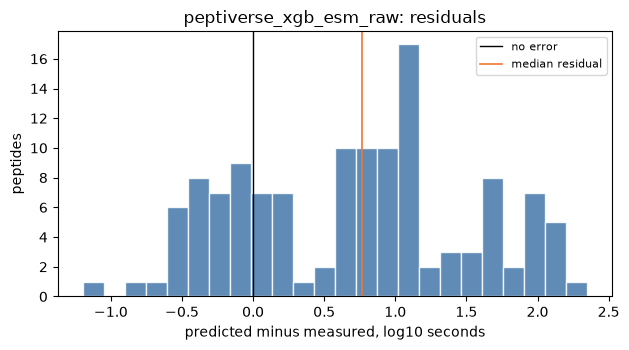

In [6]:
display(report.prediction_scatter(predictions, interval_model, title=f"{PREDICTOR}: predicted against measured"))
plt.close("all")
display(report.residual_histogram(predictions, noise_floor=noise_floor, title=f"{PREDICTOR}: residuals"))
plt.close("all")

## Question 2: does the prediction land inside the measurement interval

Two intervals are scored. The first is the interval this project estimates around the
**measured** point with the logarithmic relative-width estimator. The second is the
conformal interval the authors ship with the artifact, evaluated both in the space its
calibration was fitted in and in the space the published inference script applies it to.

In [7]:
interval_keys = ["interval_hit_rate", "interval_hit_rate_in_domain", "extrapolated_share",
                 "median_interval_width_log10", "median_interval_factor"]
display(pd.Series({k: summary.get(k) for k in interval_keys}).to_frame("value")
        .style.format(precision=3).set_caption("Agreement with the estimated measurement interval"))

model_intervals = report.load_result(PREDICTOR, "model_intervals.json", COHORT)
if model_intervals:
    display(pd.DataFrame(model_intervals).T.style.format(precision=3)
            .set_caption("Conformal interval shipped with the artifact: coverage of our measurements"))
else:
    print("This artifact ships no usable conformal calibration.")

,value
interval_hit_rate,0.227
interval_hit_rate_in_domain,0.108
extrapolated_share,0.422
median_interval_width_log10,0.441
median_interval_factor,2.759


,model_interval_coverage,model_interval_median_width_log10,model_interval_median_factor,space
target,0.984,5.462,289819.950,target
output,0.984,5.462,289819.950,output


## Question 3: duration class

The easiest version of the task: does the prediction fall into the right duration class
of the data contract (short below 30 min, medium up to 6 h, long above)? The majority
class baseline is the reference.

,value
accuracy,0.320
balanced_accuracy,0.359
majority_class_accuracy,0.430
adjacent_or_exact_accuracy,0.758
mean_class_distance,0.922
recall_short,0.000
recall_medium,0.164
recall_long,0.914
predicted_share_short,0.000
predicted_share_medium,0.148


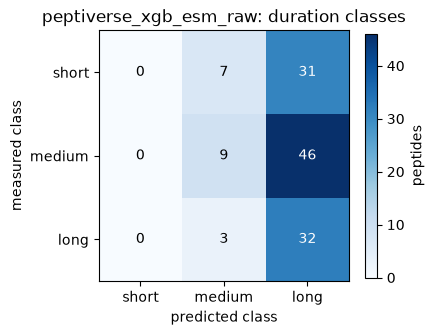

In [8]:
class_keys = ["accuracy", "balanced_accuracy", "majority_class_accuracy", "adjacent_or_exact_accuracy",
              "mean_class_distance", "recall_short", "recall_medium", "recall_long",
              "predicted_share_short", "predicted_share_medium", "predicted_share_long",
              "predicted_class_entropy_classes"]
display(pd.Series({k: summary.get(k) for k in class_keys}).to_frame("value")
        .style.format(precision=3).set_caption("Duration-class assignment"))

confusion = report.load_result(PREDICTOR, "confusion_matrix.csv", COHORT)
display(report.confusion_heatmap(confusion, title=f"{PREDICTOR}: duration classes"))
plt.close("all")

## Training overlap

Part of our cohort appears in the published training table. Accuracy is therefore split
into the overlapping part, which reports the model's fit to its own training data, and
the held-out part, which is the only honest estimate of transfer to our measurements.

In [9]:
overlap_keys = [k for k in summary if k.startswith(("training_overlap", "heldout_", "trainingoverlap_"))]
display(pd.Series({k: summary[k] for k in overlap_keys}).to_frame("value")
        .style.format(precision=3).set_caption("Overlap with the PeptiVerse training set"))

source_keys = [k for k in summary if k.startswith(("source_overlap", "sourceheldout_", "sourceoverlap_", "training_source"))]
if source_keys:
    display(pd.Series({k: summary[k] for k in source_keys}).to_frame("value")
            .style.format(precision=3)
            .set_caption("Overlap with this model's own training source inside our dataset"))

,value
training_overlap_peptides,26.000
training_overlap_share,0.203
heldout_peptides,102.000
heldout_mae_log10,0.855
heldout_rmse_log10,1.056
heldout_median_absolute_log10,0.784
heldout_bias_log10,0.674
heldout_r2,-0.700
heldout_pearson_r,-0.017
heldout_spearman_rho,-0.027


## Numerical cost

Latency of one peptide, throughput of a batch, and the projection to the batch sizes an
optimisation loop needs. The representation backbone dominates the cost, not the
regression head.

,predictor,device,batch_size,seconds_median,seconds_min,seconds_per_peptide,peptides_per_second,peak_gpu_megabytes
0,peptiverse_xgb_esm_raw,cuda,1,0.0469,0.0458,0.0469,21.3010,2691.4688
1,peptiverse_xgb_esm_raw,cuda,10,0.1975,0.1959,0.0197,50.6404,2705.6241
2,peptiverse_xgb_esm_raw,cuda,100,1.3022,1.3008,0.0130,76.7909,2739.4796
3,peptiverse_xgb_esm_raw,cuda,1000,12.7495,12.7130,0.0127,78.4345,2739.4796


,value
predictor,peptiverse_xgb_esm_raw
device,cuda
peptides,30
seconds_per_peptide_median,0.046768
seconds_per_peptide_mean,0.047828
peptides_per_second,21.382027
total_seconds,1.434849


,predictor,peptides,batched_seconds,unbatched_seconds,batching_speedup,reference_batch_size
0,peptiverse_xgb_esm_raw,1,0.013,0.047,3.668,1000
1,peptiverse_xgb_esm_raw,1000,12.749,46.768,3.668,1000
2,peptiverse_xgb_esm_raw,100000,1274.948,4676.825,3.668,1000


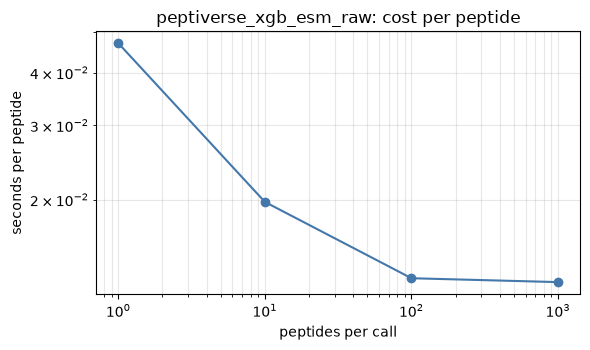

In [10]:
service_keys = [k for k in summary if k.startswith("service_")]
if service_keys:
    display(pd.Series({k: summary[k] for k in service_keys}).to_frame("value")
            .style.set_caption("Requests sent to the operator for this evaluation"))
    delay = summary.get("service_crawl_delay_seconds", 20.0)
    sent = summary.get("service_requests_sent", 0)
    peptides = summary["peptides"]
    print(f"{sent} requests for {peptides} peptides, two per batch (submit and collect).")
    print(f"At the {delay:.0f} s crawl delay that is about {sent * delay / 60:.1f} min of wall clock,")
    print(f"or {sent * delay / max(peptides, 1):.1f} s per peptide, dominated entirely by politeness.")
    print(f"A thousand peptides would need about {2 * np.ceil(1000 / 64) * delay / 60:.0f} min at 64 per batch.")
else:
    batch_cost = report.load_result(PREDICTOR, "cost_batched.csv", COHORT)
    unbatched = report.load_result(PREDICTOR, "cost_unbatched.json", COHORT)
    projection = report.load_result(PREDICTOR, "cost_projection.csv", COHORT)
    display(batch_cost.style.format(precision=4).set_caption("Measured cost per batch size"))
    display(pd.Series(unbatched).to_frame("value").style.set_caption("Single-peptide calls, as the published script scores"))
    display(projection.style.format(precision=3).set_caption("Projected wall-clock cost"))
    display(report.cost_curve(batch_cost, title=f"{PREDICTOR}: cost per peptide"))
    plt.close("all")

## Sensitivity to a single substitution

Three tests, in increasing strength. A complete substitution scan measures whether the
output moves at all and whether the movement depends on the edited position. A
permutation test keeps the composition and only reorders residues, separating a
positional model from a composition-only one. Measured parent-variant pairs test the
direction of the predicted change against experiment.

,length,variants,parent_prediction_log10,max_absolute_delta_log10,median_absolute_delta_log10,std_delta_log10,max_fold_change,identical_prediction_share,below_noise_floor_share,position_variance_share,most_sensitive_position,stabilizing_variants,destabilizing_variants
mean,10.7083,203.4583,4.4141,0.1323,0.0261,0.0341,1.3641,0.0000,nan,0.1657,4.1667,103.4583,100.0000
50%,9.5000,180.5000,4.4474,0.1234,0.0116,0.0292,1.3287,0.0000,nan,0.1224,2.0000,80.0000,97.0000
min,5.0000,95.0000,4.2373,0.0380,0.0045,0.0106,1.0915,0.0000,nan,0.0157,0.0000,15.0000,7.0000
max,23.0000,437.0000,4.4970,0.2239,0.0918,0.0673,1.6747,0.0000,nan,0.4670,17.0000,335.0000,236.0000


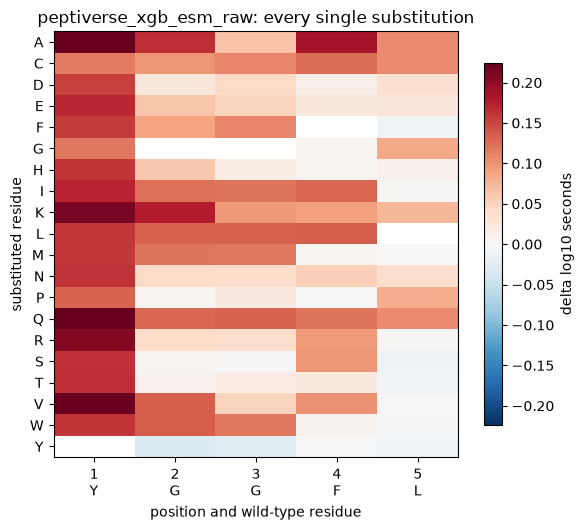

In [11]:
scan = report.load_result(PREDICTOR, "mutational_scan.csv", COHORT)
scan_summary = report.load_result(PREDICTOR, "scan_summary.csv", COHORT)
permutation = report.load_result(PREDICTOR, "permutation_test.csv", COHORT)
gradients = report.load_result(PREDICTOR, "gradient_agreement.csv", COHORT)

display(scan_summary.describe().loc[["mean", "50%", "min", "max"]].style.format(precision=4)
        .set_caption("Substitution scan over the selected peptides"))
display(report.scan_heatmap(scan, title=f"{PREDICTOR}: every single substitution"))
plt.close("all")

,permutations,max_absolute_permutation_delta_log10,median_absolute_permutation_delta_log10,std_permutation_delta_log10
mean,10.0000,0.0594,0.0260,0.0213
50%,10.0000,0.0347,0.0111,0.0156
max,10.0000,0.1217,0.0995,0.0508


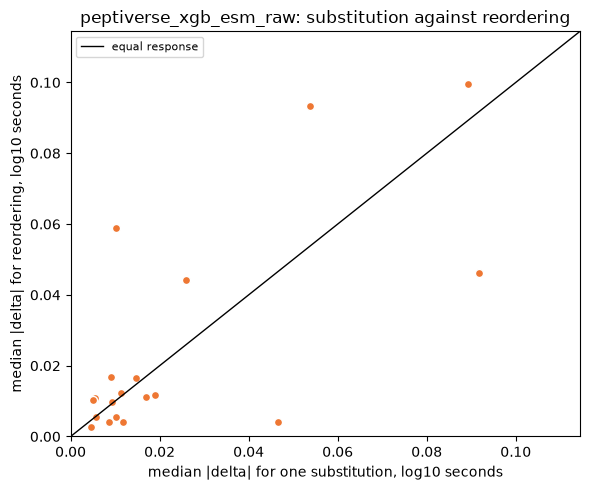

Input gradients are unavailable for this artifact: peptiverse_xgb_esm_raw is tree-based and has no input gradient


In [12]:
display(permutation.describe().loc[["mean", "50%", "max"]].style.format(precision=4)
        .set_caption("Reordering the same composition"))
display(report.permutation_comparison(scan_summary, permutation, title=f"{PREDICTOR}: substitution against reordering"))
plt.close("all")

if "available" in gradients and bool(gradients.available.any()):
    display(gradients.style.format(precision=3).set_caption("Input gradients against the finite-difference scan"))
else:
    print("Input gradients are unavailable for this artifact:",
          gradients.reason.iloc[0] if "reason" in gradients else "tree-based estimator")

,value
pairs_pairs,9.000
pairs_minimum_effect,0.100
pairs_sign_agreement,0.444
pairs_spearman_delta,0.083
pairs_mae_delta_log10,0.418
pairs_median_absolute_measured_delta,0.383
pairs_median_absolute_predicted_delta,0.006
pairs_predicted_to_measured_effect_ratio,0.015


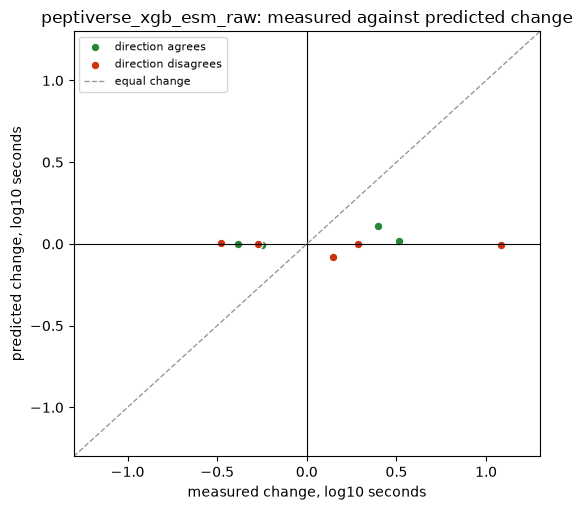

In [13]:
pairs = report.load_result(PREDICTOR, "measured_pairs.csv", COHORT)
pair_keys = [k for k in summary if k.startswith("pairs_")]
if pair_keys:
    display(pd.Series({k: summary[k] for k in pair_keys}).to_frame("value")
            .style.format(precision=3).set_caption("Agreement with measured single substitutions"))
if pairs is not None and len(pairs):
    display(report.measured_pairs_scatter(pairs, title=f"{PREDICTOR}: measured against predicted change"))
    plt.close("all")

## Verdict for this artifact

Each statement below is a threshold comparison on the numbers above, not an
interpretation.

In [14]:
for line in report.verdict_lines(summary):
    print("-", line)

- Does not order our peptides: Spearman 0.011, which is indistinguishable from chance.
- Worse than answering the cohort median: MAE 0.881 against 0.676 log10 (factor 7.6 against 4.7), so it is not calibrated for our cohort.
- Duration class accuracy 0.320, below the majority-class baseline 0.430.
- Lands inside the estimated measurement interval for 23% of peptides.
- 20% of the cohort appears in the published training set; on the held-out part Spearman is -0.027.
- Reacts to a single substitution with median |delta| 0.012 log10 (factor 1.03).
- Reordering produces 0.96 of the substitution response, so residue order matters, but less than replacing a residue outright.
- On 9 measured single-substitution pairs the predicted direction agrees 44% of the time.
- Predicted substitution effects are 0.01 times the measured ones (measured median 0.38 log10).
